# SOM ile Müşteri Segmentasyonu

Bu çalışmada, denetimsiz öğrenen bir yapay sinir ağı olan **SOM (Self-Organizing Map / Kendi Kendini Düzenleyen Harita)** kullanılarak iki farklı gerçek veri setindeki müşteriler davranışlarına göre gruplara ayrılmıştır:

1. **AVM müşterileri:** Bir alışveriş merkezinin 200 müşterisi yaş, gelir ve harcama skoruna göre 5 kümeye ayrılır ve mağazanın odaklanması gereken hedef müşteri grubu belirlenir.
2. **Kredi kartı kullanıcıları:** Yaklaşık 9 000 kredi kartı kullanıcısı 6 aylık kart kullanım verilerine göre 3 kümeye ayrılır ve müşteriler güvenilir / orta düzey / riskli olarak gruplanır.

### SOM nasıl çalışır?
SOM, Teuvo Kohonen tarafından geliştirilmiş bir yapay sinir ağıdır. Ağ, bir ızgara üzerine dizilmiş nöronlardan oluşur ve her nöronun girdi verisiyle aynı boyutta bir **ağırlık vektörü** vardır. Eğitim sırasında her adımda:

1. Veri setinden bir örnek seçilir.
2. Ağırlıkları bu örneğe en çok benzeyen nöron bulunur. Bu nörona **BMU (Best Matching Unit / en iyi eşleşen nöron)** denir.
3. BMU ve haritadaki komşularının ağırlıkları örneğe biraz daha yaklaştırılır.
4. Öğrenme katsayısı ve komşuluk yarıçapı zamanla küçülür.

Eğitim sonunda **birbirine benzeyen müşteriler haritada yan yana** düşer. Böylece 3 ya da 17 boyutlu veri, gözle incelenebilen 2 boyutlu bir haritaya dönüşür.

Bu çalışmada her iki veri setinde de aynı adımlar izlenmiştir: veri temizlenir ve 0-1 aralığına ölçeklenir, 20×20'lik bir SOM ağı eğitilir, her müşteri BMU'sunun harita üzerindeki konumuna yerleştirilir, bu konumlar **K-Means** ile kümelenir ve son olarak kümelerin profilleri incelenerek yorumlanır.

## Kurulum
İlk olarak SimpSOM kütüphanesi kurulur. Veri setlerini doğrudan Kaggle'dan indirmek için `kagglehub` kütüphanesi de kurulur.

In [1]:
!pip install -q SimpSOM kagglehub

Ardından gerekli kütüphaneler eklenir. Sonuçların her çalıştırmada aynı çıkması için sabit bir tohum (`SEED`) belirlenir ve grafiklerin ortak görünüm ayarları yapılır.

In [2]:
#Gerekli kütüphanelerin eklenmesi
import os, glob, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import RegularPolygon
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
import simpsom as sps
import kagglehub
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

warnings.filterwarnings("ignore")
SEED = 42

#Grafik ayarları
PALET = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
ISARET = ["o", "s", "^", "D", "P"]
GRI = "#b5b4ae"
YAZI = "#3d3c39"
MAVI_SKALA = LinearSegmentedColormap.from_list("mavi", ["#f3f7fd", "#a9c8f0", "#2a78d6", "#0e3a78"])
IKI_YON = LinearSegmentedColormap.from_list("iki_yon", ["#2a78d6", "#f1f0ec", "#eb6834"])
plt.rcParams.update({
    "figure.dpi": 100, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.grid": True, "grid.color": "#ebeae5", "axes.axisbelow": True,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": YAZI, "xtick.color": YAZI, "ytick.color": YAZI,
    "font.size": 9, "legend.frameon": False,
})

Her iki veri setinde de kullanılacak yardımcı fonksiyonlar tanımlanır:
- `veri_yukle`: Veri setini Kaggle'dan indirir. İndirilemezse Colab'da bilgisayardan CSV dosyası seçmek için pencere açar.
- `som_haritasi_ciz`: Eğitilen SOM'u altıgen hücreler halinde çizer. Solda U-matris, sağda kümelerin harita üzerindeki bölgeleri gösterilir.

In [3]:
def veri_yukle(kaggle_kimligi):
    try:
        klasor = kagglehub.dataset_download(kaggle_kimligi)
        dosyalar = glob.glob(klasor + "/**/*.csv", recursive=True)
    except Exception:
        dosyalar = []
    if not dosyalar:  #Kaggle'dan inmezse CSV dosyasını bilgisayardan seçin
        from google.colab import files
        dosyalar = list(files.upload().keys())
    return pd.read_csv(dosyalar[0])


def _altigenler(ax, merkezler, renkler):
    hucreler = [RegularPolygon((x, y), 6, radius=1 / np.sqrt(3)) for x, y in merkezler]
    ax.add_collection(PatchCollection(hucreler, facecolor=renkler, edgecolor="white", linewidth=0.5))
    ax.set_xlim(merkezler[:, 0].min() - 1, merkezler[:, 0].max() + 1)
    ax.set_ylim(merkezler[:, 1].min() - 1, merkezler[:, 1].max() + 1)
    ax.set_aspect("equal"); ax.axis("off")


def som_haritasi_ciz(net, bmu, kmeans, isimler, renkler):
    merkezler = np.array([n.pos for n in net.node_list])
    umatris = np.array(net.diff_graph(show=False, print_out=False, returns=True))
    noron_kumesi = kmeans.predict(merkezler)               #her nöronun düştüğü küme
    sayac = np.bincount(bmu, minlength=len(merkezler))     #her nörondaki müşteri sayısı

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
    _altigenler(ax1, merkezler, MAVI_SKALA((umatris - umatris.min()) / np.ptp(umatris)))
    ax1.set_title("U-Matris (koyu = küme sınırı)")

    acik = lambda r: tuple(c + (1 - c) * 0.72 for c in to_rgb(r))
    _altigenler(ax2, merkezler, [acik(renkler[k]) for k in noron_kumesi])
    dolu = sayac > 0
    ax2.scatter(merkezler[dolu, 0], merkezler[dolu, 1], s=4 + 12 * np.sqrt(sayac[dolu]),
                c=[renkler[k] for k in noron_kumesi[dolu]], edgecolor="white", linewidth=0.5)
    ax2.set_title("Küme bölgeleri")
    ax2.legend(handles=[Line2D([], [], marker="h", ls="", markersize=9, color=renkler[k], label=isimler[k])
                        for k in sorted(isimler)], loc="upper left", bbox_to_anchor=(1, 1))
    fig.tight_layout(); plt.show()


def bar_etiketle(ax, degerler, toplam=None, bicim="{:.0f}"):
    for i, d in enumerate(degerler):
        metin = bicim.format(d) + (f" (%{100 * d / toplam:.0f})" if toplam else "")
        ax.text(d, i, "  " + metin, va="center", color=YAZI, fontsize=8.5)

---
## 1. AVM Müşterilerinin Kümelenmesi

Bu uygulamada bir alışveriş merkezinin 200 müşterisi SOM ile kümelenmiştir. Amaç, müşterileri gelir ve harcama alışkanlıklarına göre gruplara ayırarak mağazanın **hangi müşterilere odaklanması gerektiğini** belirlemektir. Veri setine [Kaggle](https://www.kaggle.com/shwetabh123/mall-customers) üzerinden erişilebilir.

**Problemin tanımı:** Mağaza müşterilerini gruplara ayırmak ve hedef müşteri grubunu belirlemek.

**Problemin girdileri:**
- Yaş
- Yıllık gelir (bin $)
- Harcama skoru (1-100)

**Problemin çıktıları:**
- Yüksek gelir – yüksek harcama (hedef müşteri)
- Yüksek gelir – düşük harcama
- Orta gelir – orta harcama
- Düşük gelir – yüksek harcama
- Düşük gelir – düşük harcama

Beş adet çıktı belirlendiği için küme sayısı **5** olarak tasarlanmıştır.

### Veri setinin yüklenmesi
Veri seti Kaggle'dan indirilir. Sütun isimleri daha kolay okunması için Türkçeleştirilir.

In [4]:
#Verisetinin yüklenmesi
avm = veri_yukle("shwetabh123/mall-customers")
avm = avm.rename(columns={"Genre": "Cinsiyet", "Gender": "Cinsiyet", "Age": "Yaş",
                          "Annual Income (k$)": "Gelir", "Spending Score (1-100)": "Harcama"})
print(avm.shape)
avm.head()

(200, 5)


,CustomerID,Cinsiyet,Yaş,Gelir,Harcama
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
avm.describe().round(1)

,CustomerID,Yaş,Gelir,Harcama
count,200.0,200.0,200.0,200.0
mean,100.5,38.8,60.6,50.2
std,57.9,14.0,26.3,25.8
min,1.0,18.0,15.0,1.0
25%,50.8,28.8,41.5,34.8
50%,100.5,36.0,61.5,50.0
75%,150.2,49.0,78.0,73.0
max,200.0,70.0,137.0,99.0


Veri setinde eksik değer bulunmamaktadır. Kümelemeye geçmeden önce değişkenlerin dağılımına bakılır. Kesikli çizgiler ortalamayı gösterir.

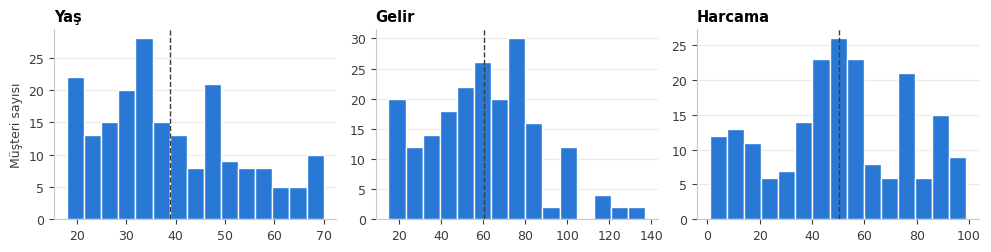

In [6]:
#Değişkenlerin dağılımı
fig, eksenler = plt.subplots(1, 3, figsize=(10, 2.6))
for ax, sutun in zip(eksenler, ["Yaş", "Gelir", "Harcama"]):
    ax.hist(avm[sutun], bins=15, color=PALET[0], edgecolor="white")
    ax.axvline(avm[sutun].mean(), color=YAZI, ls="--", lw=1)
    ax.set_title(sutun); ax.grid(axis="x", visible=False)
eksenler[0].set_ylabel("Müşteri sayısı")
fig.tight_layout(); plt.show()

Gelir ve harcama skoru birlikte çizildiğinde müşterilerin gözle de seçilebilen gruplar oluşturduğu görülür. SOM'un bu yapıyı yakalaması beklenir.

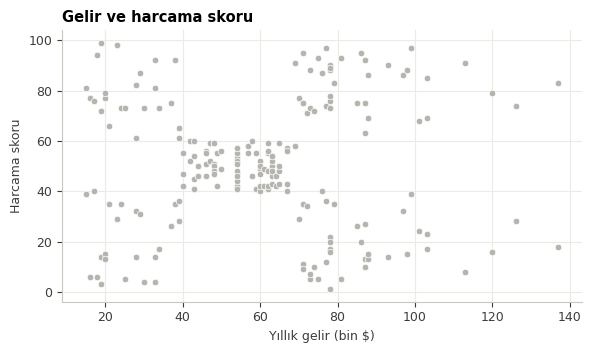

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.scatter(avm["Gelir"], avm["Harcama"], s=22, color=GRI, edgecolor="white", linewidth=0.5)
ax.set_xlabel("Yıllık gelir (bin $)"); ax.set_ylabel("Harcama skoru")
ax.set_title("Gelir ve harcama skoru")
fig.tight_layout(); plt.show()

### Veri ön işleme
`CustomerID` sadece müşteri numarası olduğu, cinsiyet ise sayısal olmadığı için modelden çıkarılır. Değişkenler farklı ölçeklerde olduğu için (örneğin yaş 18-70, gelir 15-137 arasında) tüm değerler **0-1 aralığına ölçeklenir**. Böylece hiçbir değişken büyük sayılı olduğu için kümelemeye baskın gelmez.

In [8]:
#Kullanılacak değişkenlerin seçilmesi ve ölçeklenmesi
avm_ozellikler = ["Yaş", "Gelir", "Harcama"]
X_avm = MinMaxScaler().fit_transform(avm[avm_ozellikler])
pd.DataFrame(X_avm, columns=avm_ozellikler).head().round(3)

,Yaş,Gelir,Harcama
0,0.019,0.000,0.388
1,0.058,0.000,0.816
2,0.038,0.008,0.051
3,0.096,0.008,0.776
4,0.250,0.016,0.398


### Ağın oluşturulması ve eğitilmesi
20×20 boyutunda bir ağ oluşturulur. Ağın başlangıç ağırlıkları veriden (PCA ile) elde edilir ve periyodik sınır koşulları (PBC) aktif edilir. PBC sayesinde haritanın kenarları birbirine bağlanır ve kenardaki nöronlar dezavantajlı olmaz.

Daha sonra ağ eğitilir. Öğrenme katsayısı **0.01**, epok sayısı **10 000** olarak belirlenmiştir.

In [9]:
#Ağın oluşturulması
random.seed(SEED); np.random.seed(SEED)
net_avm = sps.SOMNet(20, 20, X_avm, PBC=True, random_seed=SEED)

Periodic Boundary Conditions active.
The weights will be initialized with PCA.


In [10]:
#Ağın eğitilmesi
net_avm.train(train_algo="online", epochs=10000, start_learning_rate=0.01)

The map will be trained with the online algorithm.
Training SOM... done!


### Kümeleme
Eğitimin ardından her veri noktası 2 boyutlu harita üzerine yerleştirilir: her müşteriye en çok benzeyen nöronun (BMU) konumu bulunur. Bu konumlar K-Means ile 5 kümeye ayrılır. Örneklerin hangi kümeye ait olduğu `fit_predict()` komutu ile belirlenir ve her müşteri için 0 ile 4 arasında bir küme numarası elde edilir.

In [11]:
#Veri noktalarının 2 boyutlu haritaya gömülmesi ve kümeleme
bmu_avm = np.array(net_avm.find_bmu_ix(X_avm))
hrt_avm = np.array([net_avm.node_list[i].pos for i in bmu_avm])

kmeans_avm = KMeans(n_clusters=5, max_iter=300, n_init=10, random_state=0)
avm["Küme"] = kmeans_avm.fit_predict(hrt_avm)
avm["Küme"].value_counts().sort_index()

Küme
0    54
1    36
2    27
3    45
4    38
Name: count, dtype: int64

Küme numaraları (0, 1, 2…) tek başına bir anlam taşımaz ve farklı çalıştırmalarda değişebilir. Bu nedenle kümeleri yorumlamak için her kümenin ortalama değerlerine bakılır ve kümeler bu ortalamalara göre isimlendirilir:
- Kümenin ortalama geliri/harcaması tüm müşterilerin alt üçte birlik dilimindeyse **Düşük**, ortadaysa **Orta**, üst üçte birlik dilimindeyse **Yüksek** olarak adlandırılır.
- Geliri ve harcaması birlikte en yüksek olan küme **hedef müşteri** grubudur ve ★ ile işaretlenir.

In [12]:
#Kümelerin ortalama değerlerine göre isimlendirilmesi
def seviye(deger, seri):
    alt, ust = seri.quantile([1/3, 2/3])
    return "Düşük" if deger < alt else ("Yüksek" if deger > ust else "Orta")

avm_ort = avm.groupby("Küme")[avm_ozellikler].mean()
z = (avm_ort - avm[avm_ozellikler].mean()) / avm[avm_ozellikler].std()
hedef = (z["Gelir"] + z["Harcama"]).idxmax()

avm_isim = {k: ("★ " if k == hedef else "") +
               f"{seviye(r['Gelir'], avm['Gelir'])} gelir · {seviye(r['Harcama'], avm['Harcama'])} harcama"
            for k, r in avm_ort.iterrows()}
AVM_RENK = {k: PALET[k] for k in avm_isim}

ozet = avm_ort.round(1)
ozet.insert(0, "Segment", ozet.index.map(avm_isim))
ozet["Müşteri sayısı"] = avm["Küme"].value_counts()
ozet["Kadın oranı (%)"] = (avm.groupby("Küme")["Cinsiyet"].apply(lambda s: (s == "Female").mean()) * 100).round(0)
ozet.sort_values("Gelir")

,Segment,Yaş,Gelir,Harcama,Müşteri sayısı,Kadın oranı (%)
Küme,,,,,,
0,Düşük gelir · Orta harcama,37.6,29.7,48.3,54,59.0
2,Orta gelir · Orta harcama,56.4,50.7,53.7,27,56.0
4,Yüksek gelir · Düşük harcama,37.2,72.9,31.2,38,53.0
3,Yüksek gelir · Orta harcama,34.4,74.1,41.5,45,53.0
1,★ Yüksek gelir · Yüksek harcama,34.8,84.2,81.4,36,58.0


### SOM haritası
- **U-Matris (sol):** Her altıgen bir nöronu gösterir. Renk, nöronun komşularına olan ortalama uzaklığıdır. Açık renkli alanlar birbirine benzeyen müşterilerin toplandığı bölgeler, koyu hücreler ise gruplar arasındaki doğal sınırlardır.
- **Küme bölgeleri (sağ):** Haritanın K-Means ile bölündüğü 5 bölge. Noktalar o nörona yerleşen müşterileri gösterir; nokta büyüdükçe müşteri sayısı artar.

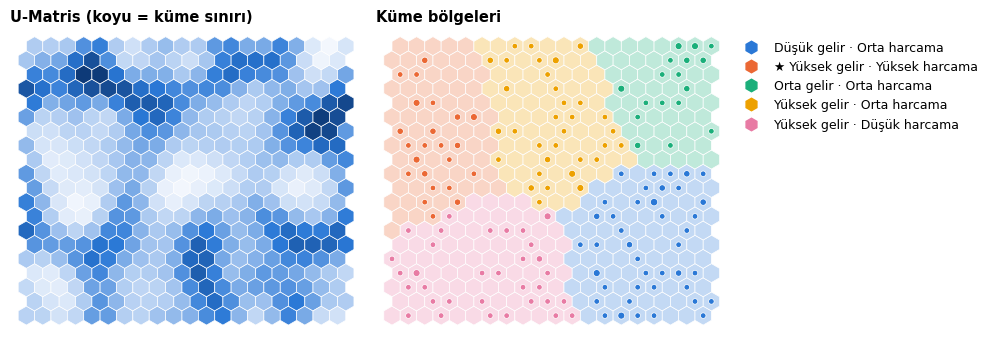

In [13]:
som_haritasi_ciz(net_avm, bmu_avm, kmeans_avm, avm_isim, AVM_RENK)

### Kümelerin gelir ve harcama skoruna göre gösterilmesi
SOM'un bulduğu kümeler orijinal değişkenlerin üzerine çizilir. Büyük işaretler her kümenin ortalamasını gösterir. Sağ üstteki grup (yüksek gelir, yüksek harcama) mağazanın hedef müşterisidir.

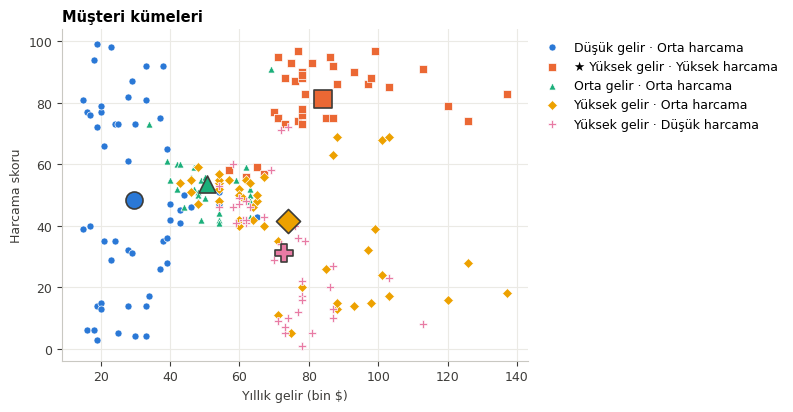

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for k in sorted(avm_isim):
    alt = avm[avm["Küme"] == k]
    ax.scatter(alt["Gelir"], alt["Harcama"], s=26, marker=ISARET[k], color=AVM_RENK[k],
               edgecolor="white", linewidth=0.5, label=avm_isim[k])
    ax.scatter(alt["Gelir"].mean(), alt["Harcama"].mean(), s=150, marker=ISARET[k],
               color=AVM_RENK[k], edgecolor=YAZI, linewidth=1.2, zorder=4)
ax.set_xlabel("Yıllık gelir (bin $)"); ax.set_ylabel("Harcama skoru")
ax.set_title("Müşteri kümeleri")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout(); plt.show()

### Kümelerin profilleri
Her grafikte kümelerin o değişkendeki ortalaması gösterilmiştir. Kesikli çizgi tüm müşterilerin ortalamasıdır; çizginin sağında kalan kümeler ortalamanın üzerindedir.

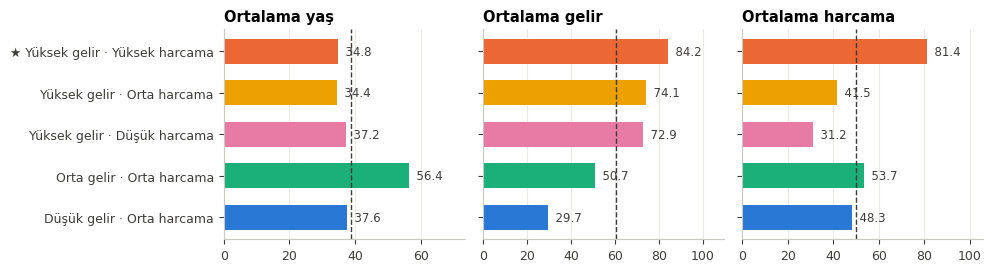

In [15]:
sira = avm_ort.sort_values("Gelir").index
fig, eksenler = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
for ax, sutun in zip(eksenler, avm_ozellikler):
    degerler = avm_ort.loc[sira, sutun]
    ax.barh(range(5), degerler, color=[AVM_RENK[k] for k in sira], height=0.6)
    ax.axvline(avm[sutun].mean(), color=YAZI, ls="--", lw=1)
    bar_etiketle(ax, degerler.values, bicim="{:.1f}")
    ax.set_xlim(0, degerler.max() * 1.3)
    ax.set_title(f"Ortalama {sutun.lower()}"); ax.grid(axis="y", visible=False)
eksenler[0].set_yticks(range(5), [avm_isim[k] for k in sira])
fig.tight_layout(); plt.show()

Her kümedeki müşteri sayısı ve kümelerin yaş dağılımı:

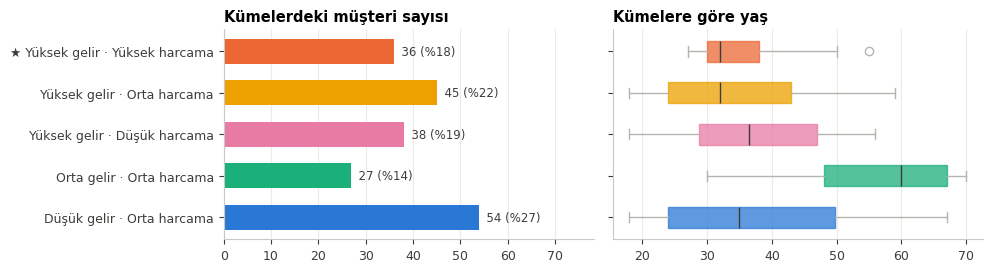

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 2.8))
sayilar = avm["Küme"].value_counts().reindex(sira)
ax1.barh(range(5), sayilar, color=[AVM_RENK[k] for k in sira], height=0.6)
bar_etiketle(ax1, sayilar.values, toplam=len(avm))
ax1.set_xlim(0, sayilar.max() * 1.45); ax1.grid(axis="y", visible=False)
ax1.set_yticks(range(5), [avm_isim[k] for k in sira])
ax1.set_title("Kümelerdeki müşteri sayısı")

kutu = ax2.boxplot([avm.loc[avm["Küme"] == k, "Yaş"] for k in sira], vert=False, positions=range(5),
                   widths=0.5, patch_artist=True, medianprops={"color": YAZI},
                   whiskerprops={"color": GRI}, capprops={"color": GRI}, flierprops={"markeredgecolor": GRI})
for parca, k in zip(kutu["boxes"], sira):
    parca.set(facecolor=AVM_RENK[k], edgecolor=AVM_RENK[k], alpha=0.75)
ax2.set_yticks(range(5), [""] * 5); ax2.set_ylim(ax1.get_ylim())
ax2.set_title("Kümelere göre yaş"); ax2.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

### Yorum
SOM haritası ve küme ortalamaları birlikte değerlendirildiğinde 200 müşteri şu beş gruba ayrılmıştır:

- **★ Yüksek gelir · yüksek harcama (36 müşteri, %18):** Ortalama 35 yaş, 84 bin $ gelir, harcama skoru 81. Mağazanın **hedef müşteri** grubudur. Bu gruba sadakat programları, VIP ayrıcalıklar ve premium ürünlerle odaklanılmalıdır.
- **Yüksek gelir · düşük harcama (38 müşteri, %19):** Ortalama 73 bin $ gelire rağmen harcama skoru 31. Harcama gücü olduğu halde mağazada az harcayan bu grup, kişiselleştirilmiş kampanyalarla kazanılabilecek en büyük potansiyeldir.
- **Yüksek gelir · orta harcama (45 müşteri, %22):** Genç (ortalama 34 yaş) ve geliri yüksek bir grup. Çapraz satış ve üst ürün önerileriyle hedef gruba yaklaştırılabilir.
- **Orta gelir · orta harcama (27 müşteri, %14):** Ortalama 56 yaşıyla en yaşlı grup. İstikrarlı müşterilerdir; kalite ve hizmet odaklı iletişim uygundur.
- **Düşük gelir · orta harcama (54 müşteri, %27):** En kalabalık grup. İndirim günleri, uygun fiyatlı ürünler ve taksit seçenekleri bu grubu hedefler.

Geliri yüksek olup az harcayan iki grup birlikte müşterilerin **%41'ini** oluşturmaktadır; mağaza için en büyük büyüme fırsatı bu müşterilerdir. SOM'a gelir ve harcamanın yanında **yaş** da girdi olarak verildiği için kümeler yaşı da hesaba katmıştır. Bu nedenle yaşlı müşteriler ayrı bir küme oluştururken, düşük gelirli müşteriler (çok ve az harcayanlar) tek bir kümede birleşmiştir. Kadın müşteri oranı tüm kümelerde %53-59 arasında olduğundan cinsiyet, kümeleri ayıran bir özellik değildir.

---
## 2. Kredi Kartı Müşterilerinin Kümelenmesi

Bu uygulamada yaklaşık 9 000 kredi kartı kullanıcısının 6 aylık kullanım verileri SOM ile kümelenmiştir. Amaç, müşterileri kart kullanım davranışlarına göre **güvenilir olup olmadıklarına** göre gruplamaktır. Veri setine [Kaggle](https://www.kaggle.com/arjunbhasin2013/ccdata) üzerinden erişilebilir.

**Problemin tanımı:** Kredi kartı müşterilerini kullanım alışkanlıklarına göre gruplara ayırmak.

**Problemin girdileri:**
- Bakiye ve bakiye güncelleme sıklığı
- Harcama tutarları (tek seferlik ve taksitli)
- Nakit avans tutarı ve sıklığı
- Harcama sıklıkları ve işlem sayıları
- Kredi limiti, ödemeler, asgari ödeme
- Borcun tamamını ödeme oranı, kart süresi

**Problemin çıktıları:**
- Güvenilir müşteriler
- Orta düzey müşteriler
- Riskli müşteriler

Üç adet çıktı belirlendiği için küme sayısı **3** olarak tasarlanmıştır.

### Veri setinin yüklenmesi

In [17]:
#Verisetinin yüklenmesi
kk = veri_yukle("arjunbhasin2013/ccdata")
print(kk.shape)
kk.head()

(8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


Veri setindeki değişkenlerin anlamları:

- `BALANCE`: Hesapta kalan bakiye (borç), `BALANCE_FREQUENCY`: bakiyenin güncellenme sıklığı (0-1)
- `PURCHASES`: Toplam alışveriş tutarı, `ONEOFF_PURCHASES`: tek çekim alışveriş tutarı, `INSTALLMENTS_PURCHASES`: taksitli alışveriş tutarı
- `CASH_ADVANCE`: Çekilen nakit avans tutarı
- `PURCHASES_FREQUENCY`, `ONEOFF_PURCHASES_FREQUENCY`, `PURCHASES_INSTALLMENTS_FREQUENCY`: alışveriş sıklıkları (0-1)
- `CASH_ADVANCE_FREQUENCY`: Nakit avans çekme sıklığı (0-1), `CASH_ADVANCE_TRX`: nakit avans işlem sayısı
- `PURCHASES_TRX`: Alışveriş işlem sayısı
- `CREDIT_LIMIT`: Kredi kartı limiti
- `PAYMENTS`: Yapılan toplam ödeme, `MINIMUM_PAYMENTS`: yapılan asgari ödeme tutarı
- `PRC_FULL_PAYMENT`: Borcun tamamının ödendiği dönemlerin oranı (0-1)
- `TENURE`: Kart kullanım süresi (ay)

Eksik değerlere bakıldığında kredi limiti ve asgari ödeme sütunlarında eksik değerler olduğu görülür:

In [18]:
kk.isna().sum()[lambda s: s > 0]

CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

Parasal değişkenlerin çoğu **sağa çarpıktır**: müşterilerin büyük kısmı düşük tutarlarda yoğunlaşırken az sayıda müşteri çok yüksek değerlere sahiptir. Kesikli çizgiler medyanı gösterir.

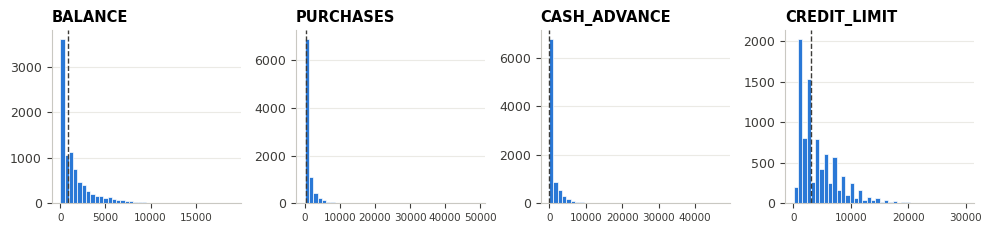

In [19]:
fig, eksenler = plt.subplots(1, 4, figsize=(10, 2.4))
for ax, sutun in zip(eksenler, ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT"]):
    ax.hist(kk[sutun].dropna(), bins=40, color=PALET[0], edgecolor="white", linewidth=0.5)
    ax.axvline(kk[sutun].median(), color=YAZI, ls="--", lw=1)
    ax.set_title(sutun); ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=7.5)
fig.tight_layout(); plt.show()

### Veri ön işleme
`CUST_ID` sadece müşteri numarası olduğu için çıkarılır. Kredi limiti ve asgari ödeme sütunlarındaki eksik değerler, aykırı değerlerden etkilenmemesi için sütunun **medyanı** ile doldurulur. Değişkenler farklı ölçeklerde olduğu için (örneğin tutarlar ile oranlar) tüm değerler **0-1 aralığına ölçeklenir**.

In [20]:
#Gereksiz sütunun çıkarılması, eksik değerlerin doldurulması ve ölçekleme
kk_ozellikler = kk.drop(columns="CUST_ID").columns
kk_temiz = kk[kk_ozellikler].fillna(kk[kk_ozellikler].median())
X_kk = MinMaxScaler().fit_transform(kk_temiz)
X_kk.shape

(8950, 17)

Değişkenler arasındaki ilişkiler korelasyon matrisi ile incelenir. Örneğin toplam harcama ile tek çekim harcama, nakit avans tutarı ile nakit avans işlem sayısı arasında güçlü bir ilişki vardır.

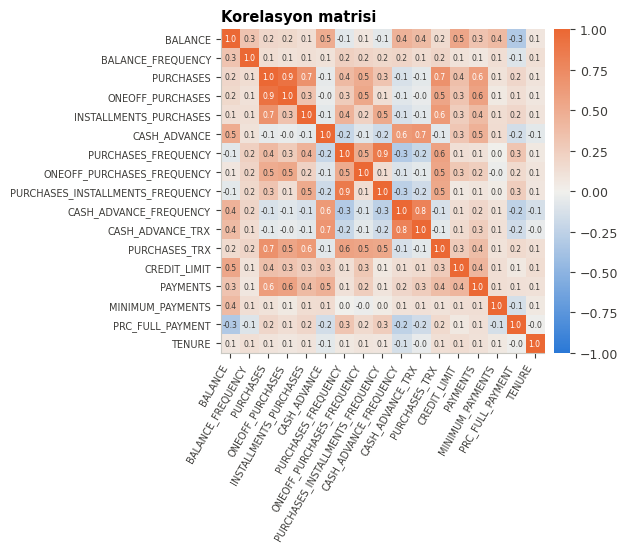

In [21]:
kor = kk_temiz.corr()
fig, ax = plt.subplots(figsize=(7, 5.6))
im = ax.imshow(kor, cmap=IKI_YON, vmin=-1, vmax=1)
ax.set_xticks(range(len(kor)), kor.columns, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(kor)), kor.columns, fontsize=7)
for i in range(len(kor)):
    for j in range(len(kor)):
        ax.text(j, i, f"{kor.iloc[i, j]:.1f}", ha="center", va="center", fontsize=5.5,
                color="white" if abs(kor.iloc[i, j]) > 0.6 else YAZI)
ax.grid(False); ax.set_title("Korelasyon matrisi")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02).outline.set_visible(False)
fig.tight_layout(); plt.show()

### Ağın oluşturulması ve eğitilmesi
İlk uygulamayla aynı şekilde 20×20 boyutunda, periyodik sınır koşulları aktif bir ağ oluşturulur ve 0.01 öğrenme katsayısı ile 10 000 epok boyunca eğitilir.

In [22]:
#Ağın oluşturulması
random.seed(SEED); np.random.seed(SEED)
net_kk = sps.SOMNet(20, 20, X_kk, PBC=True, random_seed=SEED)

Periodic Boundary Conditions active.
The weights will be initialized with PCA.


In [23]:
#Ağın eğitilmesi
net_kk.train(train_algo="online", epochs=10000, start_learning_rate=0.01)

The map will be trained with the online algorithm.
Training SOM... done!


### Kümeleme
Her müşteri BMU'sunun harita üzerindeki konumuna yerleştirilir ve bu konumlar K-Means ile 3 kümeye ayrılır. `fit_predict()` ile her müşteri için 0 ile 2 arasında bir küme numarası elde edilir.

In [24]:
#Veri noktalarının 2 boyutlu haritaya gömülmesi ve kümeleme
bmu_kk = np.array(net_kk.find_bmu_ix(X_kk))
hrt_kk = np.array([net_kk.node_list[i].pos for i in bmu_kk])

kmeans_kk = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0)
kk["Küme"] = kmeans_kk.fit_predict(hrt_kk)
kk["Küme"].value_counts().sort_index()

Küme
0    3669
1    2830
2    2451
Name: count, dtype: int64

Kümeleri güvenilir / orta düzey / riskli olarak isimlendirmek için basit bir **risk skoru** hesaplanır. Her kümenin ortalaması, tüm müşterilerin ortalamasına göre standartlaştırılır (z-skoru) ve:

$$\text{Risk} = z_{\text{bakiye}} + z_{\text{nakit avans}} + z_{\text{nakit avans sıklığı}} - z_{\text{harcama}} - z_{\text{tam ödeme oranı}}$$

Yüksek bakiye ve nakit avans kullanımı riski artırırken, kartı alışveriş için kullanmak ve borcun tamamını ödemek riski azaltır. Skoru en düşük küme *güvenilir*, en yüksek küme *riskli* olarak etiketlenir.

In [25]:
#Kümelerin risk skoruna göre isimlendirilmesi
kk_ort = kk.groupby("Küme")[kk_ozellikler].mean()
z_kk = (kk_ort - kk_temiz.mean()) / kk_temiz.std()
risk = (z_kk["BALANCE"] + z_kk["CASH_ADVANCE"] + z_kk["CASH_ADVANCE_FREQUENCY"]
        - z_kk["PURCHASES"] - z_kk["PRC_FULL_PAYMENT"])

kk_sira = risk.sort_values().index
kk_isim = dict(zip(kk_sira, ["Güvenilir", "Orta düzey", "Riskli"]))
KK_RENK = dict(zip(kk_sira, ["#1baf7a", "#eda100", "#e34948"]))

pd.DataFrame({"Segment": kk_isim, "Risk skoru": risk.round(2),
              "Müşteri sayısı": kk["Küme"].value_counts()}).loc[kk_sira]

,Segment,Risk skoru,Müşteri sayısı
Küme,,,
0,Güvenilir,-1.04,3669
1,Orta düzey,0.50,2830
2,Riskli,0.98,2451


Kümelerin tüm değişkenlerdeki ortalama değerleri:

In [26]:
#Kümelerin ortalama değerleri
tablo = kk_ort.loc[kk_sira].round(2).T
tablo.columns = [kk_isim[k] for k in kk_sira]
tablo

,Güvenilir,Orta düzey,Riskli
BALANCE,537.42,1673.12,2976.46
BALANCE_FREQUENCY,0.74,0.96,0.98
PURCHASES,491.21,1094.49,1664.23
ONEOFF_PURCHASES,147.88,768.13,1055.04
INSTALLMENTS_PURCHASES,343.67,326.68,609.40
CASH_ADVANCE,364.37,1544.08,1246.14
PURCHASES_FREQUENCY,0.50,0.39,0.59
ONEOFF_PURCHASES_FREQUENCY,0.05,0.27,0.35
PURCHASES_INSTALLMENTS_FREQUENCY,0.44,0.21,0.43
CASH_ADVANCE_FREQUENCY,0.05,0.24,0.14


### SOM haritası
U-matristeki koyu hücreler, farklı kullanım davranışlarına sahip müşteri grupları arasındaki sınırları gösterir. Sağdaki haritada harita üç bölgeye ayrılmıştır.

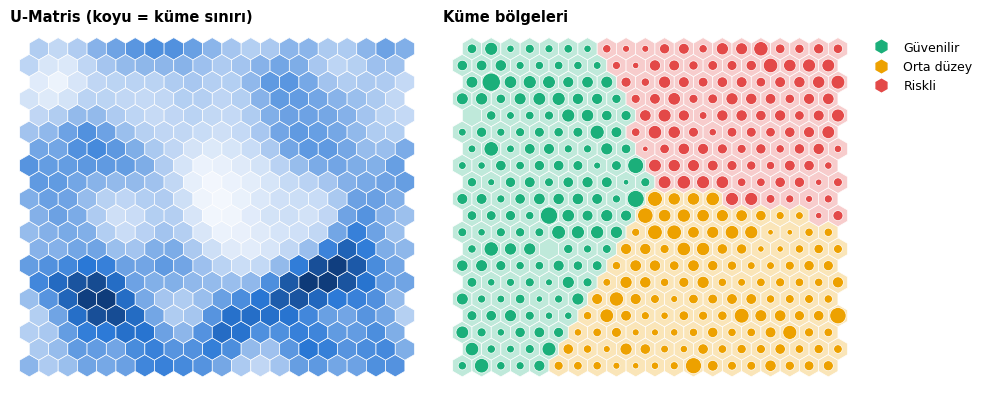

In [27]:
som_haritasi_ciz(net_kk, bmu_kk, kmeans_kk, kk_isim, KK_RENK)

### Kümelerin profilleri
Isı haritasında her hücre, küme ortalamasının genel ortalamadan ne kadar saptığını gösterir: **turuncu** hücreler ortalamanın üstünde, **mavi** hücreler altındadır. Hücrelerdeki sayılar kümenin gerçek ortalama değeridir.

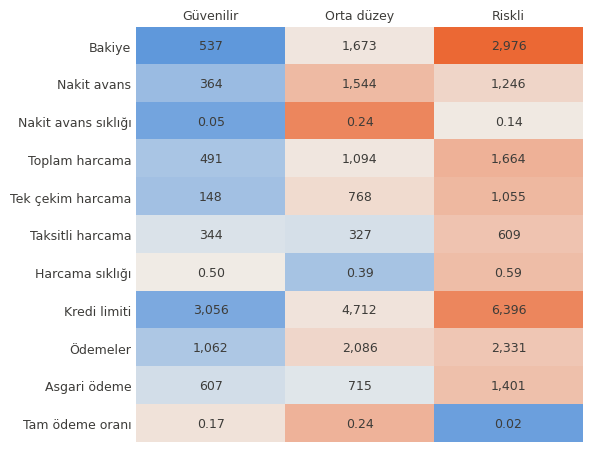

In [28]:
etiket = {"BALANCE": "Bakiye", "CASH_ADVANCE": "Nakit avans", "CASH_ADVANCE_FREQUENCY": "Nakit avans sıklığı",
          "PURCHASES": "Toplam harcama", "ONEOFF_PURCHASES": "Tek çekim harcama",
          "INSTALLMENTS_PURCHASES": "Taksitli harcama", "PURCHASES_FREQUENCY": "Harcama sıklığı",
          "CREDIT_LIMIT": "Kredi limiti", "PAYMENTS": "Ödemeler", "MINIMUM_PAYMENTS": "Asgari ödeme",
          "PRC_FULL_PAYMENT": "Tam ödeme oranı"}
onemli = list(etiket)
zz, ham = z_kk.loc[kk_sira, onemli].T, kk_ort.loc[kk_sira, onemli].T

fig, ax = plt.subplots(figsize=(6, 4.6))
s = np.abs(zz.values).max()
ax.imshow(zz, cmap=IKI_YON, vmin=-s, vmax=s, aspect="auto")
ax.set_xticks(range(3), [kk_isim[k] for k in kk_sira]); ax.xaxis.tick_top()
ax.set_yticks(range(len(onemli)), [etiket[c] for c in onemli])
ax.tick_params(length=0); ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
for i in range(len(onemli)):
    for j in range(3):
        d = ham.iloc[i, j]
        ax.text(j, i, f"{d:.2f}" if d < 1.5 else f"{d:,.0f}", ha="center", va="center", color=YAZI)
fig.tight_layout(); plt.show()

### Harcama ve nakit avansa göre kümeler
Müşteriler alışveriş tutarı ve nakit avans tutarına göre çizilmiştir. Her grafikte bir küme renkli, diğer müşteriler gri olarak gösterilir. Tutarlar çok çarpık olduğu için eksenler logaritmik ölçektedir (0 değerleri eksenin başında toplanır).

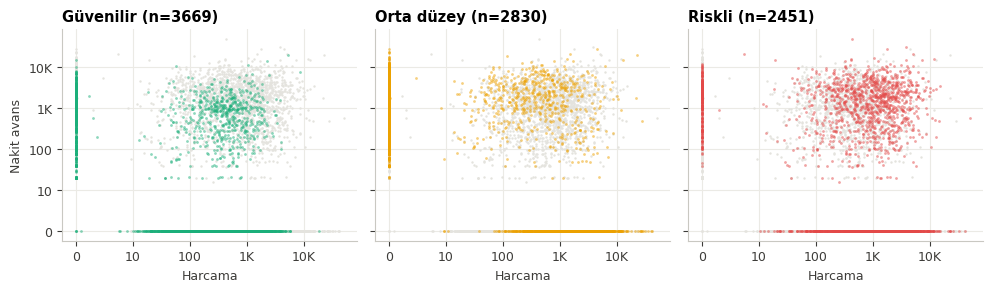

In [29]:
x, y = np.log10(kk["PURCHASES"] + 1), np.log10(kk["CASH_ADVANCE"] + 1)
fig, eksenler = plt.subplots(1, 3, figsize=(10, 3), sharex=True, sharey=True)
for ax, k in zip(eksenler, kk_sira):
    sec = kk["Küme"] == k
    ax.scatter(x[~sec], y[~sec], s=3, color="#e4e3de", linewidth=0)
    ax.scatter(x[sec], y[sec], s=4, color=KK_RENK[k], alpha=0.5, linewidth=0)
    ax.set_title(f"{kk_isim[k]} (n={sec.sum()})"); ax.set_xlabel("Harcama")
    ax.set_xticks(range(5), ["0", "10", "100", "1K", "10K"])
eksenler[0].set_yticks(range(5), ["0", "10", "100", "1K", "10K"]); eksenler[0].set_ylabel("Nakit avans")
fig.tight_layout(); plt.show()

Kümelerdeki müşteri sayısı ve dönemlerin en az yarısında borcunun tamamını ödeyen müşterilerin oranı:

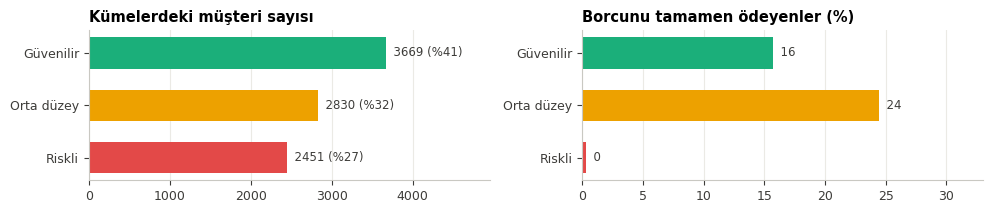

In [30]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 2.2))
sayilar = kk["Küme"].value_counts().reindex(kk_sira)
tam_odeme = kk.groupby("Küme")["PRC_FULL_PAYMENT"].apply(lambda s: (s >= 0.5).mean() * 100).reindex(kk_sira)
for ax, degerler, baslik, ek in [(ax1, sayilar, "Kümelerdeki müşteri sayısı", len(kk)),
                                 (ax2, tam_odeme, "Borcunu tamamen ödeyenler (%)", None)]:
    ax.barh(range(3), degerler, color=[KK_RENK[k] for k in kk_sira], height=0.6)
    bar_etiketle(ax, degerler.values, toplam=ek, bicim="{:.0f}")
    ax.set_yticks(range(3), [kk_isim[k] for k in kk_sira]); ax.invert_yaxis()
    ax.set_xlim(0, degerler.max() * 1.35); ax.grid(axis="y", visible=False); ax.set_title(baslik)
fig.tight_layout(); plt.show()

### Yorum
- **Güvenilir (3 669 müşteri, %41):** Bakiyesi (≈537) ve nakit avans kullanımı en düşük gruptur. Kartı küçük tutarlarda ve sıklıkla taksitli alışveriş için kullanır; borç yükü düşüktür. Bu gruba limit artışı, puan ve sadakat kampanyaları önerilebilir.
- **Orta düzey (2 830 müşteri, %32):** Bu grubu ayıran temel özellik **nakit avans** kullanımıdır (≈1 544, dönemlerin %24'ünde). Alışveriş sıklığı en düşük gruptur; buna karşın borcunu tamamen ödeme oranı en yüksek grup da budur. Pahalı nakit avans yerine ihtiyaç kredisi veya taksitli nakit seçenekleri sunulabilir.
- **Riskli (2 451 müşteri, %27):** Bakiyesi (≈2 976), kredi limiti ve asgari ödemesi en yüksek gruptur. Çok harcamasına rağmen borcunun tamamını **neredeyse hiç ödemez** (tam ödeme oranı ≈ 0.02); yani borcunu sürekli bir sonraki aya devreder. Bu müşteriler banka için faiz geliri sağlasa da temerrüt riski en yüksek gruptur ve yakından takip edilmelidir.

Sonuç olarak harcama tutarı tek başına güvenilirliği göstermez: en çok harcayan müşteriler borcunu ödemedikleri için riskli grupta yer almıştır. Nakit avans kullanımı ise finansal sıkışıklığın erken bir işareti olarak izlenmelidir.

---
## Genel Değerlendirme
SOM, 3 ve 17 boyutlu müşteri verisini komşuluk ilişkilerini koruyarak 2 boyutlu bir haritaya indirmiş ve benzer müşterileri bir araya getirmiştir. U-matris küme sınırlarını görsel olarak göstermiş, K-Means ise harita üzerindeki bölgeleri net kümelere dönüştürmüştür. Aynı yöntem, boyutları çok farklı iki veri setinde (200 × 3 ve 8 950 × 17) değişiklik yapılmadan çalışmıştır.

Yöntemin bazı sınırlılıkları da vardır. K-Means harita koordinatları üzerinde çalıştığı için periyodik sınırların (haritanın kenarlarının birleşmesi) etkisini hesaba katmaz. Kredi kartı verisi çok çarpık olduğundan Min-Max ölçekleme aykırı değerlerden etkilenir; log dönüşümü veya `RobustScaler` denenebilir. Küme sayısı problem tanımından alınmıştır; dirsek yöntemi veya siluet skoru ile veriye dayalı olarak da seçilebilir.